# Aufgabe 3 – Musterlösung
## Rückschätzung, Prognose und Managementaussage

Diese Lösung wird zusammen mit den verdeckten Istwerten erst nach dem Walkthrough veröffentlicht. Sie vergleicht bewusst einfache Verfahren: Im Zentrum stehen Zielsicht, Leakage-Schutz und der messbare Einfluss der Transformation.

## 0. Setup und Eingangskontrollen

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 30)
sns.set_theme(style="whitegrid", context="notebook")

def find_repo_root(start: Path = Path.cwd()) -> Path:
    for candidate in [start, *start.parents]:
        checkpoint = candidate / "data/checkpoints/checkpoint_02_reviewed_quality.parquet"
        actuals = candidate / "data/reference/forecast_actuals.parquet"
        if checkpoint.exists() and actuals.exists():
            return candidate
    raise FileNotFoundError(
        "Checkpoint 02 oder freigegebene Istwerte wurden nicht gefunden."
    )

ROOT = find_repo_root()
CHECKPOINT_PATH = ROOT / "data/checkpoints/checkpoint_02_reviewed_quality.parquet"
ACTUALS_PATH = ROOT / "data/reference/forecast_actuals.parquet"
WORK_DIR = ROOT / "data/work"
WORK_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_START = pd.Timestamp("2025-07-01 00:00:00")
TRAIN_END = pd.Timestamp("2025-07-25 00:00:00")
BACKCAST_INDEX = pd.date_range("2025-07-10", periods=24, freq="h")
FUTURE_INDEX = pd.date_range("2025-07-25", "2025-07-31 23:00:00", freq="h")

trips = pd.read_parquet(CHECKPOINT_PATH)

required = {
    "ingest_record_id",
    "tpep_pickup_datetime",
    "include_demand_after_quality",
    "quality_action",
}
assert required.issubset(trips.columns)
assert trips["ingest_record_id"].is_unique

print(f"Checkpoint 02: {trips.shape[0]:,} Zeilen × {trips.shape[1]} Spalten")
print("Die Istwerte werden erst im Reveal-Abschnitt geladen.")

Checkpoint 02: 200,900 Zeilen × 67 Spalten
Die Istwerte werden erst im Reveal-Abschnitt geladen.


## 1. Kleine Funktionen für zweckspezifische Datenprodukte

Die Funktionen arbeiten mit halboffenen Intervallen `[start, end)` und verändern den Input nicht. Die Rohsicht zeigt den Zustand ohne die in Aufgaben 1 und 2 erarbeiteten Entscheidungen; die Demand-Sicht zählt nur als physische Fahrt freigegebene Zeilen.

In [2]:
def build_demand_views(records, start, end):
    in_window = records["tpep_pickup_datetime"].ge(start) & records[
        "tpep_pickup_datetime"
    ].lt(end)
    raw_view = records.loc[in_window].copy()
    demand_mask = in_window & records["include_demand_after_quality"].fillna(False)
    demand_view = records.loc[demand_mask].copy()
    return raw_view, demand_view


def hourly_counts(records, start, end):
    index = pd.date_range(start, end - pd.Timedelta(hours=1), freq="h")
    counts = records.groupby(
        records["tpep_pickup_datetime"].dt.floor("h")
    ).size()
    return counts.reindex(index, fill_value=0).astype(float).rename("trips")


def error_metrics(actual, predicted):
    actual, predicted = actual.align(predicted, join="inner")
    if len(actual) == 0 or actual.isna().any() or predicted.isna().any():
        raise ValueError("Ist- und Prognosewerte müssen vollständig ausgerichtet sein.")
    absolute_error = (actual - predicted).abs()
    denominator = actual.abs().sum()
    return {
        "MAE": float(absolute_error.mean()),
        "WAPE": float(absolute_error.sum() / denominator)
        if denominator
        else np.nan,
    }


raw_view, demand_view = build_demand_views(
    trips, TRAIN_START, TRAIN_END
)
raw_hourly = hourly_counts(raw_view, TRAIN_START, TRAIN_END)
demand_hourly = hourly_counts(demand_view, TRAIN_START, TRAIN_END)

view_summary = pd.DataFrame(
    {
        "Zeilen": [len(raw_view), len(demand_view)],
        "Stunden": [len(raw_hourly), len(demand_hourly)],
        "Fahrten im Stundenraster": [raw_hourly.sum(), demand_hourly.sum()],
    },
    index=["Rohsicht", "Demand-Sicht"],
)
display(view_summary)

,Zeilen,Stunden,Fahrten im Stundenraster
Rohsicht,200893,576,200893.0
Demand-Sicht,195752,576,195752.0


In [3]:
# Automatisierte Kontrollen der Aggregation
original_probe = trips.head(20).copy(deep=True)
_ = build_demand_views(trips, TRAIN_START, TRAIN_END)
pd.testing.assert_frame_equal(trips.head(20), original_probe)

for series in (raw_hourly, demand_hourly):
    assert len(series) == 24 * 24
    assert series.index.is_monotonic_increasing
    assert series.index.is_unique
    assert not series.isna().any()
    assert series.index.min() == TRAIN_START
    assert series.index.max() == TRAIN_END - pd.Timedelta(hours=1)

assert raw_hourly.index.equals(demand_hourly.index)
assert (raw_hourly >= demand_hourly).all()
print("Aggregationskontrollen bestanden.")

Aggregationskontrollen bestanden.


## 2. Rückschätzung ohne Leakage

Alle Modellfunktionen erhalten nur die Serie ohne den 10. Juli. Die Istwerte werden separat gehalten und erst in `error_metrics()` verwendet.

In [4]:
def interpolation_backcast(observed, target_index):
    full_index = observed.index.union(target_index).sort_values()
    work = observed.reindex(full_index).astype(float)
    work.loc[target_index] = np.nan
    return work.interpolate(method="time").reindex(target_index)


def weekday_hour_median(observed, target_index):
    history = observed.rename("trips").to_frame()
    history["weekday"] = history.index.dayofweek
    history["hour"] = history.index.hour
    lookup = history.groupby(["weekday", "hour"])["trips"].median()
    prediction = [lookup.loc[(ts.dayofweek, ts.hour)] for ts in target_index]
    return pd.Series(prediction, index=target_index, dtype=float)


def calendar_features(index, origin):
    index = pd.DatetimeIndex(index)
    frame = pd.DataFrame(index=index)
    frame["hour_sin"] = np.sin(2 * np.pi * index.hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * index.hour / 24)
    frame["trend_days"] = (index - origin).total_seconds() / 86_400
    weekday = pd.get_dummies(index.dayofweek, prefix="weekday", dtype=float)
    weekday.index = index
    return pd.concat([frame, weekday], axis=1)


def linear_calendar_forecast(observed, target_index):
    assert observed.index.intersection(target_index).empty
    origin = observed.index.min()
    x_train = calendar_features(observed.index, origin)
    x_target = calendar_features(target_index, origin).reindex(
        columns=x_train.columns, fill_value=0
    )
    model = LinearRegression().fit(x_train, observed)
    return pd.Series(
        model.predict(x_target), index=target_index, dtype=float
    ).clip(lower=0)


def backcast_one_series(series, view_name, target_index):
    actual = series.reindex(target_index).copy()
    observed = series.drop(target_index)
    assert observed.index.intersection(target_index).empty

    predictions = {
        "Interpolation": interpolation_backcast(observed, target_index),
        "Wochentag/Stunde-Median": weekday_hour_median(observed, target_index),
        "Lineares Kalendermodell": linear_calendar_forecast(
            observed, target_index
        ),
    }
    rows = []
    for model_name, prediction in predictions.items():
        rows.append(
            {
                "Sicht": view_name,
                "Modell": model_name,
                **error_metrics(actual, prediction),
            }
        )
    return pd.DataFrame(rows), actual, predictions


raw_backcast, raw_backcast_actual, raw_backcast_predictions = (
    backcast_one_series(raw_hourly, "Rohsicht", BACKCAST_INDEX)
)
demand_backcast, demand_backcast_actual, demand_backcast_predictions = (
    backcast_one_series(demand_hourly, "Demand-Sicht", BACKCAST_INDEX)
)
backcast_metrics = pd.concat(
    [raw_backcast, demand_backcast], ignore_index=True
)
display(backcast_metrics.round(4))

,Sicht,Modell,MAE,WAPE
0,Rohsicht,Interpolation,196.9783,0.5380
1,Rohsicht,Wochentag/Stunde-Median,27.5417,0.0752
2,Rohsicht,Lineares Kalendermodell,83.9975,0.2294
3,Demand-Sicht,Interpolation,195.1400,0.5442
4,Demand-Sicht,Wochentag/Stunde-Median,27.2917,0.0761
5,Demand-Sicht,Lineares Kalendermodell,84.0035,0.2343


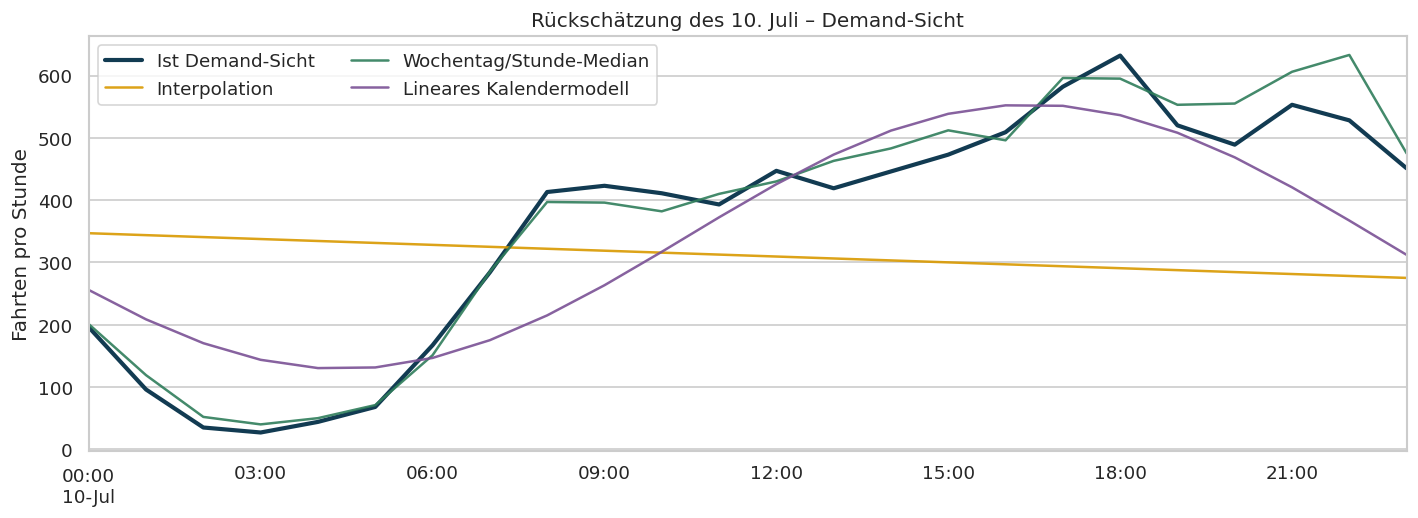

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
demand_backcast_actual.plot(
    ax=ax, label="Ist Demand-Sicht", color="#123B52", linewidth=2.5
)
colours = ["#D99900", "#2F7D5B", "#7A5195"]
for (model_name, prediction), colour in zip(
    demand_backcast_predictions.items(), colours
):
    prediction.plot(ax=ax, label=model_name, color=colour, alpha=0.9)
ax.set(
    title="Rückschätzung des 10. Juli – Demand-Sicht",
    xlabel="",
    ylabel="Fahrten pro Stunde",
)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

**Interpretation:** Die Interpolation verbindet im Wesentlichen die Randstunden einer 24-stündigen Lücke und verfehlt das Tagesprofil. Der Median derselben Wochentagsstunde nutzt die wiederkehrende Wochen- und Tagessaisonalität und erzielt hier den kleinsten Fehler. Die Differenz zwischen Roh- und Demand-Sicht ist beim Rückschätzungstag gering, weil der kontrollierte Replay nicht in diesem Fenster liegt.

## 3. Zukunftsprognosen – zunächst ohne Istwerte

Für jede Sicht werden dieselben beiden Modellklassen und derselbe Horizont verwendet. Damit lässt sich der Einfluss der Transformation von der Modellwahl trennen.

In [6]:
def seasonal_naive(training, target_index, lag_hours=168):
    lookup = target_index - pd.Timedelta(hours=lag_hours)
    prediction = pd.Series(
        training.reindex(lookup).to_numpy(), index=target_index, dtype=float
    )
    if prediction.isna().any():
        raise ValueError("Für einzelne Zielstunden fehlt der saisonale Vergleichswert.")
    return prediction


def linear_forecast(training, target_index):
    assert training.index.max() < target_index.min()
    origin = training.index.min()
    x_train = calendar_features(training.index, origin)
    x_future = calendar_features(target_index, origin).reindex(
        columns=x_train.columns, fill_value=0
    )
    model = LinearRegression().fit(x_train, training)
    return pd.Series(
        model.predict(x_future), index=target_index, dtype=float
    ).clip(lower=0)


def tidy_forecast(prediction, model_name, view_name):
    return pd.DataFrame(
        {
            "pickup_hour": prediction.index,
            "model": model_name,
            "training_view": view_name,
            "predicted_trips": prediction.to_numpy(),
        }
    )


forecasts = []
for view_name, training in {
    "Rohsicht": raw_hourly,
    "Demand-Sicht": demand_hourly,
}.items():
    forecasts.extend(
        [
            tidy_forecast(
                seasonal_naive(training, FUTURE_INDEX),
                "Saisonal-naiv (168h)",
                view_name,
            ),
            tidy_forecast(
                linear_forecast(training, FUTURE_INDEX),
                "Lineares Kalendermodell",
                view_name,
            ),
        ]
    )

forecast_table = pd.concat(forecasts, ignore_index=True)
forecast_table.to_csv(
    WORK_DIR / "task03_forecast_predictions.csv", index=False
)
display(forecast_table.head())

,pickup_hour,model,training_view,predicted_trips
0,2025-07-25 00:00:00,Saisonal-naiv (168h),Rohsicht,292.0
1,2025-07-25 01:00:00,Saisonal-naiv (168h),Rohsicht,164.0
2,2025-07-25 02:00:00,Saisonal-naiv (168h),Rohsicht,103.0
3,2025-07-25 03:00:00,Saisonal-naiv (168h),Rohsicht,74.0
4,2025-07-25 04:00:00,Saisonal-naiv (168h),Rohsicht,57.0


## 4. Plausibilitätschecks vor der Offenlegung

In [7]:
check_rows = []
for (view_name, model_name), group in forecast_table.groupby(
    ["training_view", "model"], sort=False
):
    ordered = group.sort_values("pickup_hour")
    check_rows.append(
        {
            "Sicht": view_name,
            "Modell": model_name,
            "Stunden": len(ordered),
            "eindeutige Stunden": ordered["pickup_hour"].nunique(),
            "fehlend": int(ordered["predicted_trips"].isna().sum()),
            "negativ": int(ordered["predicted_trips"].lt(0).sum()),
            "max. Stundensprung": ordered["predicted_trips"].diff().abs().max(),
        }
    )
plausibility = pd.DataFrame(check_rows)
display(plausibility.round(2))

assert forecast_table.duplicated(
    ["pickup_hour", "model", "training_view"]
).sum() == 0
assert (plausibility["Stunden"] == 168).all()
assert (plausibility["eindeutige Stunden"] == 168).all()
assert (plausibility[["fehlend", "negativ"]] == 0).all().all()
print("Formale Prognosekontrollen bestanden.")

Formale Prognosekontrollen bestanden.


,Sicht,Modell,Stunden,eindeutige Stunden,fehlend,negativ,max. Stundensprung
0,Rohsicht,Saisonal-naiv (168h),168,168,0,0,313.00
1,Rohsicht,Lineares Kalendermodell,168,168,0,0,82.86
2,Demand-Sicht,Saisonal-naiv (168h),168,168,0,0,211.00
3,Demand-Sicht,Lineares Kalendermodell,168,168,0,0,79.78


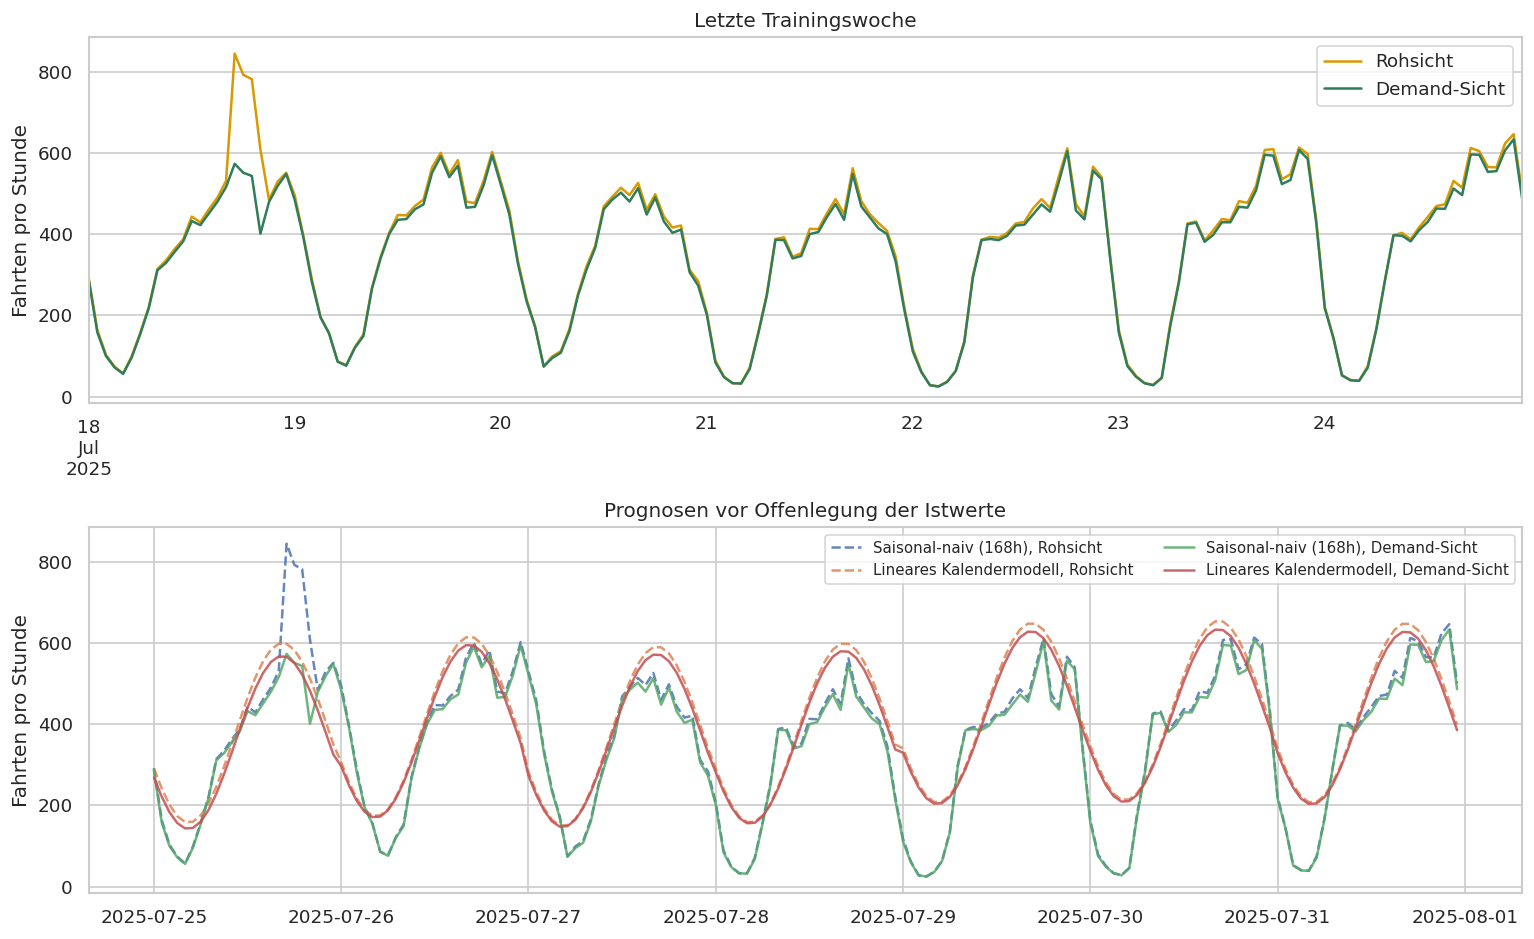

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

raw_hourly.loc["2025-07-18":"2025-07-24"].plot(
    ax=axes[0], label="Rohsicht", color="#D99900"
)
demand_hourly.loc["2025-07-18":"2025-07-24"].plot(
    ax=axes[0], label="Demand-Sicht", color="#2F7D5B"
)
axes[0].set(
    title="Letzte Trainingswoche", xlabel="", ylabel="Fahrten pro Stunde"
)
axes[0].legend()

for (view_name, model_name), group in forecast_table.groupby(
    ["training_view", "model"], sort=False
):
    linestyle = "-" if view_name == "Demand-Sicht" else "--"
    axes[1].plot(
        group["pickup_hour"],
        group["predicted_trips"],
        label=f"{model_name}, {view_name}",
        linestyle=linestyle,
        alpha=0.85,
    )
axes[1].set(
    title="Prognosen vor Offenlegung der Istwerte",
    xlabel="",
    ylabel="Fahrten pro Stunde",
)
axes[1].legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

**Erwartung vor der Offenlegung:** Die saisonal-naive Prognose dürfte das wiederkehrende Wochenprofil besser abbilden als das stark vereinfachte lineare Kalendermodell. Bei der Rohsicht besteht das zusätzliche Risiko, dass der Replay-Peak vom Freitag, 18. Juli, durch die 168-Stunden-Verzögerung auf den nächsten Freitag kopiert wird. Deshalb erwarten wir die saisonale Baseline auf der Demand-Sicht als beste Kombination. Das ist eine vorab dokumentierte Hypothese, noch kein Ergebnis.

## 5. Reveal: Evaluation mit den freigegebenen Istwerten

Erst ab hier werden die Zukunfts-Istwerte mit den zuvor erzeugten Prognosen verbunden.

In [9]:
actuals = pd.read_parquet(ACTUALS_PATH)
assert actuals["pickup_hour"].is_unique
assert actuals.shape == (168, 2)
assert pd.DatetimeIndex(actuals["pickup_hour"]).equals(FUTURE_INDEX)

evaluation = forecast_table.merge(
    actuals, on="pickup_hour", how="left", validate="many_to_one"
)
assert evaluation["actual_trips"].notna().all()

evaluation_rows = []
for (view_name, model_name), group in evaluation.groupby(
    ["training_view", "model"], sort=False
):
    indexed = group.set_index("pickup_hour")
    evaluation_rows.append(
        {
            "Sicht": view_name,
            "Modell": model_name,
            **error_metrics(
                indexed["actual_trips"], indexed["predicted_trips"]
            ),
        }
    )
future_metrics = pd.DataFrame(evaluation_rows).sort_values("WAPE")
future_metrics.to_csv(
    WORK_DIR / "task03_forecast_evaluation.csv", index=False
)
display(future_metrics.round(4))

,Sicht,Modell,MAE,WAPE
2,Demand-Sicht,Saisonal-naiv (168h),42.2083,0.1136
0,Rohsicht,Saisonal-naiv (168h),45.0833,0.1214
3,Demand-Sicht,Lineares Kalendermodell,83.0854,0.2237
1,Rohsicht,Lineares Kalendermodell,86.0583,0.2317


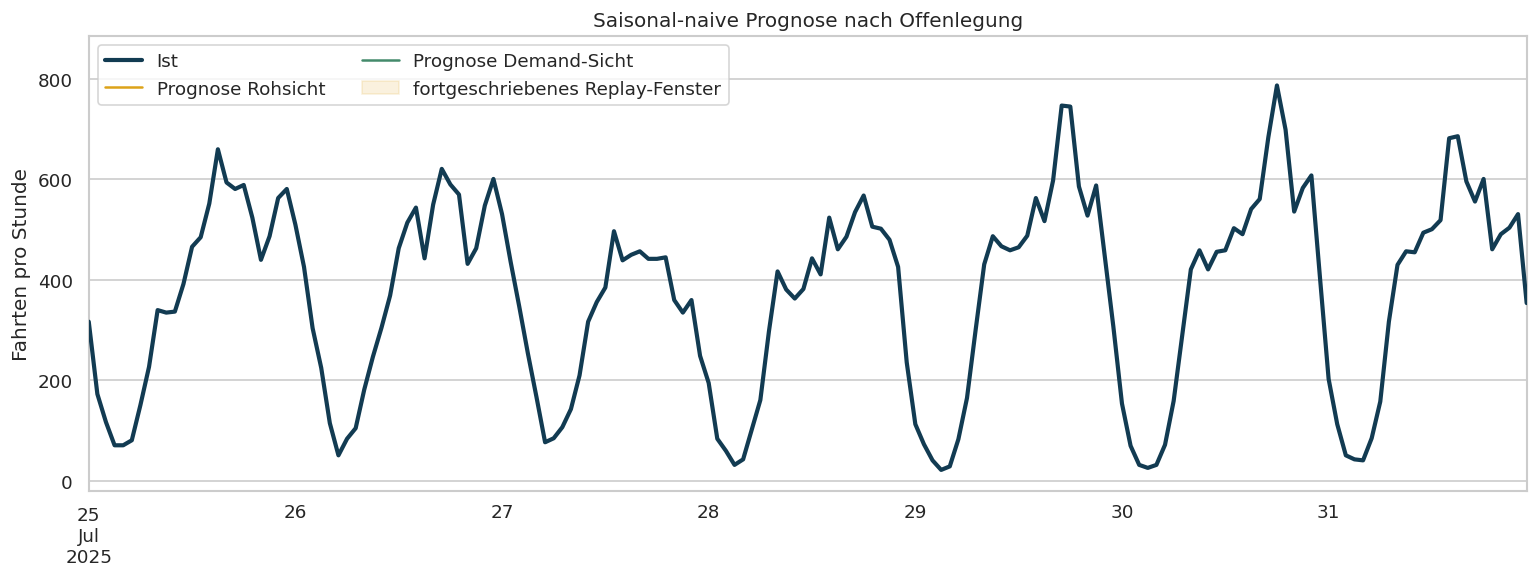

In [10]:
actual_future = actuals.set_index("pickup_hour")["actual_trips"]
fig, ax = plt.subplots(figsize=(13, 5))
actual_future.plot(
    ax=ax, label="Ist", color="#123B52", linewidth=2.5, zorder=5
)
selected = forecast_table[
    forecast_table["model"].eq("Saisonal-naiv (168h)")
]
for view_name, group in selected.groupby("training_view", sort=False):
    colour = "#D99900" if view_name == "Rohsicht" else "#2F7D5B"
    ax.plot(
        group["pickup_hour"],
        group["predicted_trips"],
        label=f"Prognose {view_name}",
        color=colour,
        alpha=0.9,
    )
ax.axvspan(
    pd.Timestamp("2025-07-25 17:00"),
    pd.Timestamp("2025-07-25 21:00"),
    color="#D99900",
    alpha=0.13,
    label="fortgeschriebenes Replay-Fenster",
)
ax.set(
    title="Saisonal-naive Prognose nach Offenlegung",
    xlabel="",
    ylabel="Fahrten pro Stunde",
)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

In [11]:
seasonal = future_metrics[
    future_metrics["Modell"].eq("Saisonal-naiv (168h)")
].set_index("Sicht")
mae_improvement = seasonal.loc["Rohsicht", "MAE"] - seasonal.loc[
    "Demand-Sicht", "MAE"
]
wape_pp_improvement = 100 * (
    seasonal.loc["Rohsicht", "WAPE"]
    - seasonal.loc["Demand-Sicht", "WAPE"]
)

print(f"MAE-Verbesserung durch Demand-Sicht: {mae_improvement:.3f} Fahrten/Stunde")
print(f"WAPE-Verbesserung: {wape_pp_improvement:.2f} Prozentpunkte")

assert seasonal.loc["Demand-Sicht", "WAPE"] < seasonal.loc[
    "Rohsicht", "WAPE"
]
best = future_metrics.iloc[0]
assert best["Sicht"] == "Demand-Sicht"
assert best["Modell"] == "Saisonal-naiv (168h)"
print("Die vorab formulierte Rangfolge wird durch den Holdout bestätigt.")

MAE-Verbesserung durch Demand-Sicht: 2.875 Fahrten/Stunde
WAPE-Verbesserung: 0.77 Prozentpunkte
Die vorab formulierte Rangfolge wird durch den Holdout bestätigt.


## 6. Managementnachricht

> Im Rohbestand wurden wiederholt eingelesene Fahrtereignisse und einzelne physikalisch nicht plausible Datensätze gefunden. Für die Nachfrageprognose haben wir technische Replays, Gegenbuchungen als zusätzliche Fahrten und klaren Noise ausgeschlossen, ohne plausible Fernfahrten pauschal zu entfernen. Im verdeckten Zeitraum erreichte die saisonal-naive Prognose auf der bereinigten Nachfragesicht einen WAPE von 11,36 % gegenüber 12,14 % auf der Rohsicht. Sie schnitt zugleich deutlich besser ab als das getestete lineare Kalendermodell. Wir empfehlen die bereinigte saisonale Baseline als transparenten Ausgangspunkt, verbunden mit laufendem Monitoring der Replay- und Quarantäneregeln. Die Auswertung zeigt einen belastbaren Zusammenhang mit der Datenbereinigung, ersetzt aber keine technische Root-Cause-Analyse des Ingest-Vorfalls.

Die sechs Sätze benennen Datenprodukt, Vergleich, Kennzahl, Empfehlung und Grenze. Der Unterschied von rund 0,77 **Prozentpunkten** wird nicht als 0,77 Prozent Verbesserung bezeichnet.

## 7. Identischer KI-Auftrag und nachvollziehbare Prüfung

In [12]:
best_row = future_metrics.iloc[0]
shared_prompt = f'''Du unterstützt die Kommunikation eines Prognosevergleichs.

Ziel: Formuliere höchstens sechs Sätze für das Management.
Nachfragesicht: technische Replays, Gegenbuchungen als zusätzliche Fahrten und klarer Noise ausgeschlossen; plausible Extremfälle nicht pauschal gelöscht.
Bestes Verfahren: {best_row["Modell"]} auf {best_row["Sicht"]}.
Bestes Ergebnis: MAE {best_row["MAE"]:.4f}, WAPE {100 * best_row["WAPE"]:.2f} %.
Saisonale Baseline Rohsicht: WAPE {100 * seasonal.loc["Rohsicht", "WAPE"]:.2f} %.
Saisonale Baseline Demand-Sicht: WAPE {100 * seasonal.loc["Demand-Sicht", "WAPE"]:.2f} %.
Grenze: Der Vergleich belegt keine technische Ursache aller Peaks und garantiert keine künftige Verbesserung.

Anforderungen: Gib Zahlen exakt wieder, unterscheide Prozent und Prozentpunkte, erfinde keine Ursache und nenne eine nächste betriebliche Massnahme.'''

print(shared_prompt)

Du unterstützt die Kommunikation eines Prognosevergleichs.

Ziel: Formuliere höchstens sechs Sätze für das Management.
Nachfragesicht: technische Replays, Gegenbuchungen als zusätzliche Fahrten und klarer Noise ausgeschlossen; plausible Extremfälle nicht pauschal gelöscht.
Bestes Verfahren: Saisonal-naiv (168h) auf Demand-Sicht.
Bestes Ergebnis: MAE 42.2083, WAPE 11.36 %.
Saisonale Baseline Rohsicht: WAPE 12.14 %.
Saisonale Baseline Demand-Sicht: WAPE 11.36 %.
Grenze: Der Vergleich belegt keine technische Ursache aller Peaks und garantiert keine künftige Verbesserung.

Anforderungen: Gib Zahlen exakt wieder, unterscheide Prozent und Prozentpunkte, erfinde keine Ursache und nenne eine nächste betriebliche Massnahme.


Kopiert den Prompt unverändert in ChatGPT und Claude Code. Bewertet beide Antworten anhand derselben Kriterien; Stil ist kein Ersatz für korrekte Zahlen und nachvollziehbare Annahmen.

| Prüfkriterium | Erwartung | typische Fehlleistung |
|---|---|---|
| Zahlen | stimmen mit `future_metrics` überein | Rundung oder Sicht vertauscht |
| WAPE | relativer absoluter Fehler | als «Genauigkeit» bezeichnet |
| Prozentpunkte | Differenz zweier Prozentwerte | mit Prozent verwechselt |
| Kausalität | Zusammenhang, kein Ursachenbeweis | Replay als Ursache aller Peaks |
| Modellauswahl | folgt Holdout-WAPE und Zweck | komplexeres Modell automatisch bevorzugt |
| Codeänderung | begrenzt und als Diff prüfbar | Pfade oder andere Dateien mitverändert |

**Best Practices:** Erst Ziel, Datensicht und Metrik festlegen; identischen Kontext verwenden; Zahlen aus der Evaluation gegenprüfen; Änderungen als kleinen Diff kontrollieren; KI-Ausgaben als Entwurf behandeln. Ein kontextarmer Auftrag wie «erstelle die beste Prognose» lädt dagegen zu erfundenen Annahmen, unnötiger Modellkomplexität und Leakage ein.

## Decision Log der Referenzlösung

| Entscheidung | Evidenz | Konsequenz |
|---|---|---|
| Roh- und Demand-Sicht getrennt evaluieren | identische Modelle und Zeitgrenzen | Cleaning-Effekt bleibt vom Modelleffekt unterscheidbar |
| vollständiges Stundenraster verwenden | 576 kontrollierte Trainingsstunden | Nullstunden und Lücken werden explizit |
| 10. Juli vollständig aus Training entfernen | disjunkte Indizes | kein Leakage beim Backcast |
| Wochentag/Stunde-Median als Backcast-Baseline | geringster MAE und WAPE | einfache Saisonalität schlägt Interpolation |
| 168h-Baseline vor Reveal festlegen | wiederkehrendes Wochenprofil | transparente, reproduzierbare Prognose |
| Demand-Sicht empfehlen | niedrigerer Holdout-WAPE | Replay-Peak wird nicht fortgeschrieben |
| keine Kausaldiagnose behaupten | beobachtender Modellvergleich | technische Root-Cause bleibt separate Aufgabe |

## Kernaussage

Die Qualität einer Prognose beginnt vor dem Modell. Reproduzierbare Ereignislogik, zweckspezifische Views und ehrliches Backtesting sind wertvoller als ein komplexeres Verfahren auf einer unklar definierten Datengrundlage.